<a href="https://colab.research.google.com/github/krishiv274/Signal2Space/blob/main/notebooks/03_floor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/krishiv274/Signal2Space.git

Cloning into 'Signal2Space'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 25 (delta 3), reused 22 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 1.62 MiB | 3.97 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [2]:
!ls -R Signal2Space

Signal2Space:
data  figures  notebooks  predictions  README.md  results  src

Signal2Space/data:
raw_data

Signal2Space/data/raw_data:
trainingData.csv  validationData.csv

Signal2Space/figures:
building_feature_importance.png

Signal2Space/notebooks:
02_building.ipynb

Signal2Space/predictions:
building__ival.csv	  building_seed1__test.csv
building_seed0__test.csv  building_seed2__test.csv

Signal2Space/results:
building_experiments.csv  building_tuning.csv

Signal2Space/src:
features.py


In [3]:
import pandas as pd

df = pd.read_csv("Signal2Space/predictions/building__ival.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (3718, 11)

Columns:
['row_id', 'b_true', 'f_true', 'x_true', 'y_true', 'b_pred', 'f_pred', 'x_pred', 'y_pred', 'USERID', 'PHONEID']


,row_id,b_true,f_true,x_true,y_true,b_pred,f_pred,x_pred,y_pred,USERID,PHONEID
0,2,1,2,-7519.152400,4.864950e+06,1,-1,-1,-1,2,23
1,6,1,2,-7519.152400,4.864950e+06,1,-1,-1,-1,2,23
2,8,1,2,-7559.497300,4.864888e+06,1,-1,-1,-1,2,23
3,9,1,2,-7510.437173,4.864949e+06,1,-1,-1,-1,2,23
4,13,1,2,-7559.782000,4.864871e+06,1,-1,-1,-1,2,23


In [4]:
with open("Signal2Space/src/features.py", "r") as f:
    print(f.read())

import numpy as np
import pandas as pd

def make_features(dbm, mask):
    d = dbm.to_numpy(dtype=float)
    m = mask.to_numpy().astype(bool)
    obs = np.where(m, d, np.nan)
    return pd.DataFrame({
        "n_heard": m.sum(axis=1),
        "max_rssi": np.nanmax(obs, axis=1),
        "mean_rssi": np.nanmean(obs, axis=1),
        "std_rssi": np.nanstd(obs, axis=1),
        "n_strong": (obs > -70).sum(axis=1),
        "top1_ap": d.argmax(axis=1),
    }, index=dbm.index)



In [5]:
import os

print(os.listdir("Signal2Space/notebooks"))

['02_building.ipynb']


In [6]:
import nbformat

nb = nbformat.read(
    "Signal2Space/notebooks/02_building.ipynb",
    as_version=4
)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "markdown":
        print(f"\n--- MARKDOWN CELL {i} ---")
        print(cell.source[:1500])
    elif cell.cell_type == "code":
        print(f"\n--- CODE CELL {i} ---")
        print(cell.source[:2000])


--- CODE CELL 0 ---
# Load the data
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

--- CODE CELL 1 ---
# Load cleaned training data
train_clean = pd.read_csv("cleaned_train.csv")
WAPS = [c for c in train_clean.columns if c.startswith("WAP")]

print(train_clean.shape, len(WAPS))

--- CODE CELL 2 ---
# Create groups
groups = (train_clean["BUILDINGID"].astype(str) + "_" +
          train_clean["FLOOR"].astype(str) + "_" +
          train_clean["SPACEID"].astype(str))

--- CODE CELL 3 ---
# Internal split
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, iv_idx = next(splitter.split(train_clean, groups=groups))

itrain = train_clean.iloc[tr_idx].reset_index(drop=True)
ival = train_clean.iloc[iv_idx].reset_index(drop=True)

print(len(itrain), len(ival))

--- CODE CELL 4 ---
# Load test files
te_dbm = pd.read_csv("validation_wifi_dbm.csv")
te_mask = pd.read_csv("validation_wifi_mask.csv")
te_lab = pd.read_csv("val

In [7]:
import os

for root, dirs, files in os.walk("Signal2Space"):
    dirs[:] = [d for d in dirs if d != ".git"]
    for file in files:
        if file.endswith((".csv", ".py", ".ipynb")):
            print(os.path.join(root, file))

Signal2Space/predictions/building_seed0__test.csv
Signal2Space/predictions/building_seed1__test.csv
Signal2Space/predictions/building__ival.csv
Signal2Space/predictions/building_seed2__test.csv
Signal2Space/data/raw_data/validationData.csv
Signal2Space/data/raw_data/trainingData.csv
Signal2Space/results/building_tuning.csv
Signal2Space/results/building_experiments.csv
Signal2Space/src/features.py
Signal2Space/notebooks/02_building.ipynb


In [8]:
import pandas as pd

iv = pd.read_csv("Signal2Space/predictions/building__ival.csv")
train = pd.read_csv("Signal2Space/data/raw_data/trainingData.csv")

print("Internal validation predictions:", iv.shape)
print("Raw training data:", train.shape)

print("\nPrediction columns:")
print(iv.columns.tolist())

print("\nBuilding distribution:")
print(iv["b_pred"].value_counts().sort_index())

print("\nFloor distribution:")
print(iv["f_true"].value_counts().sort_index())

Internal validation predictions: (3718, 11)
Raw training data: (19937, 529)

Prediction columns:
['row_id', 'b_true', 'f_true', 'x_true', 'y_true', 'b_pred', 'f_pred', 'x_pred', 'y_pred', 'USERID', 'PHONEID']

Building distribution:
b_pred
0    1072
1    1041
2    1605
Name: count, dtype: int64

Floor distribution:
f_true
0     796
1    1060
2     824
3     876
4     162
Name: count, dtype: int64


In [9]:
import pandas as pd

train = pd.read_csv("Signal2Space/data/raw_data/trainingData.csv")
iv = pd.read_csv("Signal2Space/predictions/building__ival.csv")

print("Training columns:")
print(train.columns.tolist())

print("\nTraining rows:", len(train))
print("Internal validation rows:", len(iv))

print("\nFirst few validation row IDs:")
print(iv["row_id"].head(10).tolist())

print("\nDuplicate row IDs:", iv["row_id"].duplicated().sum())
print("Missing floor labels:", iv["f_true"].isna().sum())
print("Missing building predictions:", iv["b_pred"].isna().sum())

Training columns:
['WAP001', 'WAP002', 'WAP003', 'WAP004', 'WAP005', 'WAP006', 'WAP007', 'WAP008', 'WAP009', 'WAP010', 'WAP011', 'WAP012', 'WAP013', 'WAP014', 'WAP015', 'WAP016', 'WAP017', 'WAP018', 'WAP019', 'WAP020', 'WAP021', 'WAP022', 'WAP023', 'WAP024', 'WAP025', 'WAP026', 'WAP027', 'WAP028', 'WAP029', 'WAP030', 'WAP031', 'WAP032', 'WAP033', 'WAP034', 'WAP035', 'WAP036', 'WAP037', 'WAP038', 'WAP039', 'WAP040', 'WAP041', 'WAP042', 'WAP043', 'WAP044', 'WAP045', 'WAP046', 'WAP047', 'WAP048', 'WAP049', 'WAP050', 'WAP051', 'WAP052', 'WAP053', 'WAP054', 'WAP055', 'WAP056', 'WAP057', 'WAP058', 'WAP059', 'WAP060', 'WAP061', 'WAP062', 'WAP063', 'WAP064', 'WAP065', 'WAP066', 'WAP067', 'WAP068', 'WAP069', 'WAP070', 'WAP071', 'WAP072', 'WAP073', 'WAP074', 'WAP075', 'WAP076', 'WAP077', 'WAP078', 'WAP079', 'WAP080', 'WAP081', 'WAP082', 'WAP083', 'WAP084', 'WAP085', 'WAP086', 'WAP087', 'WAP088', 'WAP089', 'WAP090', 'WAP091', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP096', 'WAP097', 'WAP098', '

In [10]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

train = pd.read_csv("Signal2Space/data/raw_data/trainingData.csv")
iv = pd.read_csv("Signal2Space/predictions/building__ival.csv")

# Recreate Member 2's split exactly
groups = (
    train["BUILDINGID"].astype(str) + "_" +
    train["FLOOR"].astype(str) + "_" +
    train["SPACEID"].astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

tr_idx, iv_idx = next(splitter.split(train, groups=groups))
expected = train.iloc[iv_idx].reset_index(drop=True)

print("Expected validation rows:", len(expected))
print("Saved prediction rows:", len(iv))

print(
    "Floor labels match:",
    np.array_equal(expected["FLOOR"].to_numpy(), iv["f_true"].to_numpy())
)

print(
    "Building labels match:",
    np.array_equal(expected["BUILDINGID"].to_numpy(), iv["b_true"].to_numpy())
)

Expected validation rows: 3852
Saved prediction rows: 3718
Floor labels match: False
Building labels match: False


In [11]:
train = pd.read_csv("Signal2Space/data/raw_data/trainingData.csv")

print("Original rows:", len(train))
print("Exact duplicate rows:", train.duplicated().sum())
print("Rows with all WAPs missing:", (train.filter(regex="^WAP").eq(100).all(axis=1)).sum())
print("Rows with RELATIVEPOSITION:", train["RELATIVEPOSITION"].nunique())

Original rows: 19937
Exact duplicate rows: 637
Rows with all WAPs missing: 76
Rows with RELATIVEPOSITION: 2


In [12]:
print("Saved row ID range:", iv["row_id"].min(), "to", iv["row_id"].max())
print("First 15 saved IDs:", iv["row_id"].head(15).tolist())

print("\nExpected first 15 original row IDs:")
print(iv_idx[:15].tolist())

Saved row ID range: 2 to 19936
First 15 saved IDs: [2, 6, 8, 9, 13, 16, 17, 20, 39, 40, 44, 45, 46, 47, 48]

Expected first 15 original row IDs:
[2, 6, 8, 9, 13, 16, 17, 20, 39, 40, 44, 45, 46, 47, 48]


In [13]:
# Recreate the cleaning process and inspect the row IDs

clean = train.copy()
clean.insert(0, "ROW_ID", range(len(clean)))

before = len(clean)

clean = clean.drop_duplicates(
    subset=[c for c in clean.columns if c != "ROW_ID"]
)

after_duplicates = len(clean)

WAPS = [c for c in clean.columns if c.startswith("WAP")]
clean = clean.loc[~clean[WAPS].eq(100).all(axis=1)].reset_index(drop=True)

print("Original rows:", before)
print("After duplicate removal:", after_duplicates)
print("After removing rows with no WAP detected:", len(clean))

groups = (
    clean["BUILDINGID"].astype(str) + "_" +
    clean["FLOOR"].astype(str) + "_" +
    clean["SPACEID"].astype(str) + "_" +
    clean["RELATIVEPOSITION"].astype(str)
)

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

tr_idx, iv_idx = next(splitter.split(clean, groups=groups))
print("Expected internal validation rows after cleaning:", len(iv_idx))

Original rows: 19937
After duplicate removal: 19300
After removing rows with no WAP detected: 19227
Expected internal validation rows after cleaning: 3801


In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Load raw training data
train = pd.read_csv("Signal2Space/data/raw_data/trainingData.csv")

# Preserve original row IDs
train.insert(0, "ROW_ID", np.arange(len(train)))

# Remove exact duplicates, ignoring ROW_ID
train = train.drop_duplicates(
    subset=[c for c in train.columns if c != "ROW_ID"]
)

# Remove rows where every Wi-Fi access point is undetected
WAPS = [c for c in train.columns if c.startswith("WAP")]
train = train.loc[~train[WAPS].eq(100).all(axis=1)].reset_index(drop=True)

# Create groups to prevent location-related leakage
groups = (
    train["BUILDINGID"].astype(str) + "_" +
    train["FLOOR"].astype(str) + "_" +
    train["SPACEID"].astype(str) + "_" +
    train["RELATIVEPOSITION"].astype(str)
)

# Reproducible internal split
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
tr_idx, iv_idx = next(splitter.split(train, groups=groups))

itrain = train.iloc[tr_idx].reset_index(drop=True)
ival = train.iloc[iv_idx].reset_index(drop=True)

print("Training rows:", len(itrain))
print("Internal validation rows:", len(ival))
print("Training floor distribution:")
print(itrain["FLOOR"].value_counts().sort_index())
print("\nValidation floor distribution:")
print(ival["FLOOR"].value_counts().sort_index())

Training rows: 15426
Internal validation rows: 3801
Training floor distribution:
FLOOR
0    3539
1    3629
2    3786
3    3917
4     555
Name: count, dtype: int64

Validation floor distribution:
FLOOR
0     756
1    1154
2     629
3    1090
4     172
Name: count, dtype: int64


In [15]:
# Separate Wi-Fi signal strengths and detection masks
X_tr_dbm = itrain[WAPS].replace(100, -110)
X_iv_dbm = ival[WAPS].replace(100, -110)

tr_mask = itrain[WAPS].ne(100).astype(int)
iv_mask = ival[WAPS].ne(100).astype(int)

# Floor labels
y_tr = itrain["FLOOR"]
y_iv = ival["FLOOR"]

print("Training features:", X_tr_dbm.shape)
print("Validation features:", X_iv_dbm.shape)
print("Training labels:", y_tr.shape)
print("Validation labels:", y_iv.shape)

Training features: (15426, 520)
Validation features: (3801, 520)
Training labels: (15426,)
Validation labels: (3801,)


In [16]:
import sys
sys.path.insert(0, "Signal2Space/src")

from features import make_features

tr_feat = make_features(X_tr_dbm, tr_mask)
iv_feat = make_features(X_iv_dbm, iv_mask)

X_tr = pd.concat([X_tr_dbm, tr_feat], axis=1)
X_iv = pd.concat([X_iv_dbm, iv_feat], axis=1)

print("Final training matrix:", X_tr.shape)
print("Final validation matrix:", X_iv.shape)
print("Missing training values:", X_tr.isna().sum().sum())
print("Missing validation values:", X_iv.isna().sum().sum())

Final training matrix: (15426, 526)
Final validation matrix: (3801, 526)
Missing training values: 0
Missing validation values: 0


In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

rf = RandomForestClassifier(
    n_estimators=300,
    n_jobs=-1,
    random_state=42
)

rf.fit(X_tr, y_tr)
floor_pred = rf.predict(X_iv)

print("Accuracy:", round(accuracy_score(y_iv, floor_pred), 4))
print("Macro F1:", round(f1_score(y_iv, floor_pred, average="macro"), 4))
print("\nClassification report:")
print(classification_report(y_iv, floor_pred, zero_division=0))

Accuracy: 0.9803
Macro F1: 0.9777

Classification report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       756
           1       1.00      0.99      0.99      1154
           2       0.93      0.97      0.95       629
           3       0.98      0.96      0.97      1090
           4       1.00      0.95      0.97       172

    accuracy                           0.98      3801
   macro avg       0.98      0.98      0.98      3801
weighted avg       0.98      0.98      0.98      3801



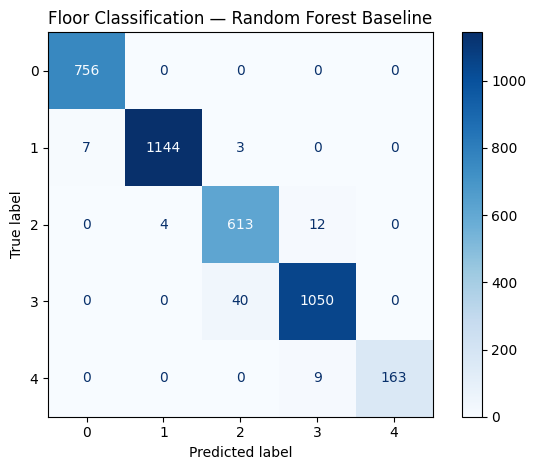

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_iv, floor_pred, labels=[0, 1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Floor Classification — Random Forest Baseline")
plt.tight_layout()
plt.show()

In [19]:
# Check exact Wi-Fi fingerprint overlap between train and validation
train_fingerprints = set(
    map(tuple, X_tr_dbm.to_numpy())
)

val_fingerprints = list(
    map(tuple, X_iv_dbm.to_numpy())
)

overlap = sum(fp in train_fingerprints for fp in val_fingerprints)

print("Validation rows:", len(val_fingerprints))
print("Exact fingerprints also in training:", overlap)
print("Overlap percentage:", round(overlap / len(val_fingerprints) * 100, 2), "%")

Validation rows: 3801
Exact fingerprints also in training: 23
Overlap percentage: 0.61 %


In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

experiments = []

# Experiment A: raw Wi-Fi signals only
rf_raw = RandomForestClassifier(
    n_estimators=300, n_jobs=-1, random_state=42
)
rf_raw.fit(X_tr_dbm, y_tr)
pred_raw = rf_raw.predict(X_iv_dbm)

experiments.append({
    "Features": "Raw Wi-Fi signals (520)",
    "Accuracy": accuracy_score(y_iv, pred_raw),
    "Macro-F1": f1_score(y_iv, pred_raw, average="macro")
})

# Experiment B: raw signals + engineered features
rf_engineered = RandomForestClassifier(
    n_estimators=300, n_jobs=-1, random_state=42
)
rf_engineered.fit(X_tr, y_tr)
pred_engineered = rf_engineered.predict(X_iv)

experiments.append({
    "Features": "Raw + engineered (526)",
    "Accuracy": accuracy_score(y_iv, pred_engineered),
    "Macro-F1": f1_score(y_iv, pred_engineered, average="macro")
})

results = pd.DataFrame(experiments)
display(results.round(4))

,Features,Accuracy,Macro-F1
0,Raw Wi-Fi signals (520),0.9811,0.9785
1,Raw + engineered (526),0.9803,0.9777


In [21]:
print("Training building distribution:")
print(itrain["BUILDINGID"].value_counts().sort_index())

print("\nValidation building distribution:")
print(ival["BUILDINGID"].value_counts().sort_index())

print("\nFloors available in each building (training):")
print(
    itrain.groupby("BUILDINGID")["FLOOR"]
    .agg(lambda x: sorted(x.unique().tolist()))
)

Training building distribution:
BUILDINGID
0    4233
1    3822
2    7371
Name: count, dtype: int64

Validation building distribution:
BUILDINGID
0    1012
1    1082
2    1707
Name: count, dtype: int64

Floors available in each building (training):
BUILDINGID
0       [0, 1, 2, 3]
1       [0, 1, 2, 3]
2    [0, 1, 2, 3, 4]
Name: FLOOR, dtype: object


In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

building_results = []
building_models = {}

for building in sorted(itrain["BUILDINGID"].unique()):
    train_mask = itrain["BUILDINGID"] == building
    val_mask = ival["BUILDINGID"] == building

    X_train_b = X_tr_dbm.loc[train_mask].reset_index(drop=True)
    y_train_b = itrain.loc[train_mask, "FLOOR"].reset_index(drop=True)

    X_val_b = X_iv_dbm.loc[val_mask].reset_index(drop=True)
    y_val_b = ival.loc[val_mask, "FLOOR"].reset_index(drop=True)

    model = RandomForestClassifier(
        n_estimators=300,
        n_jobs=-1,
        random_state=42
    )
    model.fit(X_train_b, y_train_b)
    pred_b = model.predict(X_val_b)

    building_models[building] = model

    building_results.append({
        "Building": building,
        "Train rows": len(X_train_b),
        "Validation rows": len(X_val_b),
        "Accuracy": accuracy_score(y_val_b, pred_b),
        "Macro-F1": f1_score(
            y_val_b, pred_b, average="macro", zero_division=0
        )
    })

building_results_df = pd.DataFrame(building_results)
display(building_results_df.round(4))

,Building,Train rows,Validation rows,Accuracy,Macro-F1
0,0,4233,1012,0.9881,0.9865
1,1,3822,1082,0.9519,0.9461
2,2,7371,1707,0.9918,0.9900


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Train building classifier on the same split as your floor model
building_rf = RandomForestClassifier(
    n_estimators=300,
    n_jobs=-1,
    random_state=42
)

y_building_tr = itrain["BUILDINGID"]
y_building_iv = ival["BUILDINGID"]

building_rf.fit(X_tr_dbm, y_building_tr)
b_pred_iv = building_rf.predict(X_iv_dbm)

print("Building accuracy:", round(accuracy_score(y_building_iv, b_pred_iv), 4))
print("\nBuilding classification report:")
print(classification_report(y_building_iv, b_pred_iv, zero_division=0))

Building accuracy: 1.0

Building classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1012
           1       1.00      1.00      1.00      1082
           2       1.00      1.00      1.00      1707

    accuracy                           1.00      3801
   macro avg       1.00      1.00      1.00      3801
weighted avg       1.00      1.00      1.00      3801



In [24]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np

# Route each validation row using its predicted building
two_stage_pred = np.empty(len(ival), dtype=int)

for building, model in building_models.items():
    rows = np.where(b_pred_iv == building)[0]

    if len(rows) == 0:
        continue

    two_stage_pred[rows] = model.predict(X_iv_dbm.iloc[rows])

print("Two-stage accuracy:",
      round(accuracy_score(y_iv, two_stage_pred), 4))

print("Two-stage macro-F1:",
      round(f1_score(y_iv, two_stage_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_iv, two_stage_pred, labels=[0, 1, 2, 3, 4],
    zero_division=0
))

Two-stage accuracy: 0.9795
Two-stage macro-F1: 0.977

Classification report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       756
           1       1.00      0.99      0.99      1154
           2       0.92      0.99      0.95       629
           3       0.99      0.96      0.97      1090
           4       1.00      0.95      0.97       172

    accuracy                           0.98      3801
   macro avg       0.98      0.98      0.98      3801
weighted avg       0.98      0.98      0.98      3801



In [25]:
results_summary = pd.DataFrame([
    {
        "Approach": "Flat RF - Raw Wi-Fi",
        "Accuracy": accuracy_score(y_iv, pred_raw),
        "Macro_F1": f1_score(y_iv, pred_raw, average="macro")
    },
    {
        "Approach": "Flat RF - Raw + Engineered",
        "Accuracy": accuracy_score(y_iv, pred_engineered),
        "Macro_F1": f1_score(y_iv, pred_engineered, average="macro")
    },
    {
        "Approach": "Two-stage RF",
        "Accuracy": accuracy_score(y_iv, two_stage_pred),
        "Macro_F1": f1_score(y_iv, two_stage_pred, average="macro")
    }
])

results_summary.to_csv("floor_experiments.csv", index=False)
display(results_summary.round(4))

,Approach,Accuracy,Macro_F1
0,Flat RF - Raw Wi-Fi,0.9811,0.9785
1,Flat RF - Raw + Engineered,0.9803,0.9777
2,Two-stage RF,0.9795,0.9770


In [26]:
from google.colab import files
files.download("floor_experiments.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

configs = [
    {"n_estimators": 300, "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 500, "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 300, "max_features": 0.5, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_features": "sqrt", "min_samples_leaf": 2},
    {"n_estimators": 500, "max_features": 0.5, "min_samples_leaf": 2},
]

tuning_results = []

for config in configs:
    model = RandomForestClassifier(
        **config,
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_tr_dbm, y_tr)
    pred = model.predict(X_iv_dbm)

    tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_iv, pred),
        "macro_f1": f1_score(y_iv, pred, average="macro")
    })

tuning_results = pd.DataFrame(tuning_results)
tuning_results = tuning_results.sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)

display(tuning_results)

KeyboardInterrupt: 

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

configs = [
    {"n_estimators": 100, "max_features": "sqrt", "min_samples_leaf": 1},
    {"n_estimators": 150, "max_features": 0.5, "min_samples_leaf": 1},
    {"n_estimators": 150, "max_features": "sqrt", "min_samples_leaf": 2},
]

tuning_results = []

for i, config in enumerate(configs, 1):
    start = time.time()
    print(f"Running configuration {i}/{len(configs)}: {config}", flush=True)

    model = RandomForestClassifier(
        **config,
        n_jobs=-1,
        random_state=42
    )
    model.fit(X_tr_dbm, y_tr)
    pred = model.predict(X_iv_dbm)

    tuning_results.append({
        **config,
        "accuracy": accuracy_score(y_iv, pred),
        "macro_f1": f1_score(y_iv, pred, average="macro"),
        "time_seconds": round(time.time() - start, 1)
    })

display(
    pd.DataFrame(tuning_results)
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

Running configuration 1/3: {'n_estimators': 100, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Running configuration 2/3: {'n_estimators': 150, 'max_features': 0.5, 'min_samples_leaf': 1}
Running configuration 3/3: {'n_estimators': 150, 'max_features': 'sqrt', 'min_samples_leaf': 2}


,n_estimators,max_features,min_samples_leaf,accuracy,macro_f1,time_seconds
0,150,sqrt,2,0.979479,0.977084,6.5
1,100,sqrt,1,0.976585,0.975271,12.2
2,150,0.5,1,0.967114,0.968404,47.2


In [32]:
%pip install -q xgboost

In [33]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

start = time.time()

xgb_floor = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=2,
    random_state=42
)

xgb_floor.fit(X_tr_dbm, y_tr)
xgb_pred = xgb_floor.predict(X_iv_dbm)

xgb_accuracy = accuracy_score(y_iv, xgb_pred)
xgb_macro_f1 = f1_score(y_iv, xgb_pred, average="macro")

print("XGBoost accuracy:", round(xgb_accuracy, 4))
print("XGBoost macro-F1:", round(xgb_macro_f1, 4))
print("Training + prediction time:", round(time.time() - start, 2), "seconds")

print("\nClassification report:")
print(classification_report(y_iv, xgb_pred, zero_division=0))

XGBoost accuracy: 0.9813
XGBoost macro-F1: 0.9822
Training + prediction time: 65.16 seconds

Classification report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       756
           1       1.00      0.97      0.99      1154
           2       0.94      0.98      0.96       629
           3       0.99      0.97      0.98      1090
           4       0.99      0.99      0.99       172

    accuracy                           0.98      3801
   macro avg       0.98      0.98      0.98      3801
weighted avg       0.98      0.98      0.98      3801



In [34]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Random Forest (300 trees)",
        "Accuracy": 0.9811,
        "Macro-F1": 0.9785
    },
    {
        "Model": "XGBoost",
        "Accuracy": xgb_accuracy,
        "Macro-F1": xgb_macro_f1
    }
])

display(
    comparison.sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

,Model,Accuracy,Macro-F1
0,XGBoost,0.981321,0.982181
1,Random Forest (300 trees),0.981100,0.978500


In [35]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

configs = [
    {"n_estimators": 200, "max_depth": 5, "learning_rate": 0.1},
    {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.1},
    {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.05},
]

xgb_results = []

for i, config in enumerate(configs, 1):
    start = time.time()
    print(f"Running {i}/{len(configs)}: {config}", flush=True)

    model = XGBClassifier(
        **config,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=2,
        random_state=42
    )

    model.fit(X_tr_dbm, y_tr)
    pred = model.predict(X_iv_dbm)

    xgb_results.append({
        **config,
        "accuracy": accuracy_score(y_iv, pred),
        "macro_f1": f1_score(y_iv, pred, average="macro"),
        "time_seconds": round(time.time() - start, 1)
    })

xgb_results = pd.DataFrame(xgb_results)
display(
    xgb_results.sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

Running 1/3: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
Running 2/3: {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.1}
Running 3/3: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05}


,n_estimators,max_depth,learning_rate,accuracy,macro_f1,time_seconds
0,300,4,0.10,0.980005,0.981446,35.0
1,300,6,0.05,0.979216,0.981262,43.9
2,200,5,0.10,0.979742,0.980809,30.3


In [36]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import time

seeds = [21, 42, 123]
seed_results = []

for seed in seeds:
    start = time.time()

    model = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        tree_method="hist",
        n_jobs=2,
        random_state=seed
    )

    model.fit(X_tr_dbm, y_tr)
    pred = model.predict(X_iv_dbm)

    seed_results.append({
        "seed": seed,
        "accuracy": accuracy_score(y_iv, pred),
        "macro_f1": f1_score(y_iv, pred, average="macro"),
        "time_seconds": round(time.time() - start, 1)
    })

seed_results = pd.DataFrame(seed_results)
display(seed_results.round(4))

print("Mean accuracy:", round(seed_results["accuracy"].mean(), 4))
print("Accuracy std:", round(seed_results["accuracy"].std(ddof=1), 4))
print("Mean macro-F1:", round(seed_results["macro_f1"].mean(), 4))
print("Macro-F1 std:", round(seed_results["macro_f1"].std(ddof=1), 4))

,seed,accuracy,macro_f1,time_seconds
0,21,0.9826,0.9843,49.3
1,42,0.9813,0.9822,40.1
2,123,0.9829,0.9845,40.7


Mean accuracy: 0.9823
Accuracy std: 0.0008
Mean macro-F1: 0.9836
Macro-F1 std: 0.0013


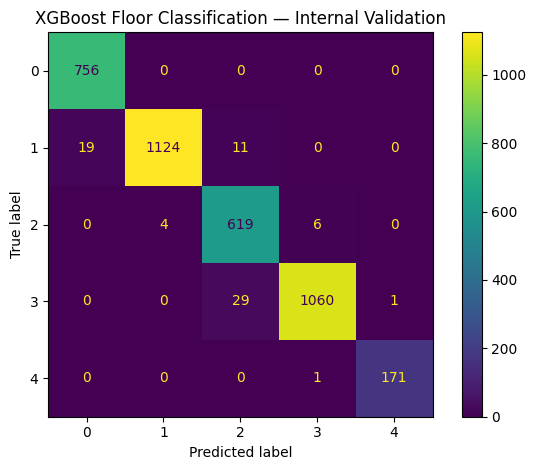

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

floor_pred = xgb_floor.predict(X_iv_dbm)

cm = confusion_matrix(
    y_iv,
    floor_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(values_format="d")
plt.title("XGBoost Floor Classification — Internal Validation")
plt.tight_layout()
plt.show()

In [38]:
import pandas as pd
from sklearn.metrics import classification_report

print(classification_report(
    y_iv,
    floor_pred,
    labels=[0, 1, 2, 3, 4],
    zero_division=0
))

errors = pd.DataFrame({
    "actual_floor": y_iv.to_numpy(),
    "predicted_floor": floor_pred
})

errors = errors[errors["actual_floor"] != errors["predicted_floor"]]

print("Total misclassified:", len(errors))
display(
    errors.groupby(["actual_floor", "predicted_floor"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       756
           1       1.00      0.97      0.99      1154
           2       0.94      0.98      0.96       629
           3       0.99      0.97      0.98      1090
           4       0.99      0.99      0.99       172

    accuracy                           0.98      3801
   macro avg       0.98      0.98      0.98      3801
weighted avg       0.98      0.98      0.98      3801

Total misclassified: 71


,actual_floor,predicted_floor,count
4,3,2,29
0,1,0,19
1,1,2,11
3,2,3,6
2,2,1,4
5,3,4,1
6,4,3,1


In [39]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from pathlib import Path

output_dir = Path("member3_outputs")
output_dir.mkdir(exist_ok=True)

# Floor predictions on the internal validation split
predictions = pd.DataFrame({
    "row_id": ival["ROW_ID"].to_numpy(),
    "f_true": y_iv.to_numpy(),
    "f_pred": floor_pred
})
predictions.to_csv(output_dir / "floor_internal_validation_predictions.csv", index=False)

# Confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=[f"actual_floor_{i}" for i in range(5)],
    columns=[f"pred_floor_{i}" for i in range(5)]
)
cm_df.to_csv(output_dir / "floor_confusion_matrix.csv")

# Summary metrics
metrics = pd.DataFrame([{
    "model": "XGBoost",
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.1,
    "validation_accuracy_seed42": accuracy_score(y_iv, floor_pred),
    "validation_macro_f1_seed42": f1_score(y_iv, floor_pred, average="macro"),
    "validation_rows": len(y_iv),
    "misclassified_rows": int((y_iv.to_numpy() != floor_pred).sum())
}])
metrics.to_csv(output_dir / "floor_metrics.csv", index=False)

print("Saved files:")
for path in sorted(output_dir.iterdir()):
    print(path)

Saved files:
member3_outputs/floor_confusion_matrix.csv
member3_outputs/floor_internal_validation_predictions.csv
member3_outputs/floor_metrics.csv


In [40]:
from pathlib import Path
import pandas as pd

output_dir = Path("member3_outputs")
output_dir.mkdir(exist_ok=True)

# Save individual seed results
seed_results.to_csv(
    output_dir / "floor_three_seed_results.csv",
    index=False
)

# Save summary statistics
seed_summary = pd.DataFrame([{
    "model": "XGBoost",
    "n_estimators": 300,
    "max_depth": 6,
    "learning_rate": 0.1,
    "seeds": "21,42,123",
    "mean_accuracy": seed_results["accuracy"].mean(),
    "std_accuracy": seed_results["accuracy"].std(ddof=1),
    "mean_macro_f1": seed_results["macro_f1"].mean(),
    "std_macro_f1": seed_results["macro_f1"].std(ddof=1)
}])

seed_summary.to_csv(
    output_dir / "floor_three_seed_summary.csv",
    index=False
)

display(seed_summary.round(4))
print("Three-seed results saved!")

,model,n_estimators,max_depth,learning_rate,seeds,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1
0,XGBoost,300,6,0.1,"21,42,123",0.9823,0.0008,0.9836,0.0013


Three-seed results saved!


In [41]:
import shutil
from google.colab import files

shutil.make_archive(
    "member3_outputs",
    "zip",
    root_dir="member3_outputs"
)

files.download("member3_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>